In [30]:
#Step#1
import numpy as np
import pandas as pd

np.random.seed(42)
n = 1000

What’s happening: seed(42) makes the random data repeatable, and n = 1000 is the number of students

In [31]:
#Create the input features
study_hours = np.random.uniform(1, 10, n).round(1)

attendance = 55 + study_hours * 3 + np.random.normal(0, 8, n)
attendance = np.clip(attendance, 40, 100).round(1)

previous_score = np.random.normal(65, 12, n)
previous_score = np.clip(previous_score, 25, 100).round(1)

assignment_score = 0.5 * previous_score + 4 * study_hours + np.random.normal(0, 8, n)
assignment_score = np.clip(assignment_score, 20, 100).round(1)

gender = np.random.choice(["Male", "Female"], n)
parent_education = np.random.choice(
    ["High School", "Bachelor", "Master"], n, p=[0.45, 0.40, 0.15]
)

 Create the input features. This generates each student’s study hours, attendance, previous score, assignment score, gender, and parent education using random numbers. Attendance and assignment scores are made to depend a little on study hours and previous score, so the data looks realistic.

In [32]:
#Create the target (Final Marks)
edu_bonus = pd.Series(parent_education).map(
    {"High School": 0, "Bachelor": 1.5, "Master": 3}
).values

final_marks = (
    5
    + 2.2 * study_hours
    + 0.15 * attendance
    + 0.40 * previous_score
    + 0.25 * assignment_score
    + edu_bonus
    + np.random.normal(0, 4, n)
)
final_marks = np.clip(final_marks, 0, 100).round(1)

Create the target (Final Marks). This builds the final marks from a hidden formula that adds up the effect of study hours, attendance, previous score, assignment score, and parent education, plus random noise. The noise stands for things we can’t measure, so no model will be perfect, and gender is left out so it has no effect.

In [33]:
#Build the table
df = pd.DataFrame({
    "Study Hours": study_hours,
    "Attendance": attendance,
    "Previous Score": previous_score,
    "Assignments Score": assignment_score,
    "Gender": gender,
    "Parent Education": parent_education,
    "Final Marks": final_marks,
})
print(df.head())
print(df.shape)

   Study Hours  Attendance  Previous Score  Assignments Score  Gender  \
0          4.4        69.6            48.1               48.6  Female   
1          9.6        73.1            64.0               65.2    Male   
2          7.6        80.8            46.9               44.2    Male   
3          6.4        79.1            74.1               54.3  Female   
4          2.4        66.7            66.0               38.7  Female   

  Parent Education  Final Marks  
0      High School         55.2  
1      High School         74.9  
2      High School         63.2  
3      High School         75.4  
4         Bachelor         55.2  
(1000, 7)


Build the table. This puts all the columns into one pandas table (DataFrame) with clear names and prints the first rows and the shape. The shape should be (1000, 7), meaning 1000 students and 7 columns.

In [34]:
#Make it messy on purpose
# 30 missing values in Attendance, 25 in Previous Score, 20 in Parent Education
for col, k in [("Attendance", 30), ("Previous Score", 25), ("Parent Education", 20)]:
    idx = np.random.choice(df.index, k, replace=False)
    df.loc[idx, col] = np.nan

df.to_csv("student_data.csv", index=False)
print(df.isna().sum())

Study Hours           0
Attendance           30
Previous Score       25
Assignments Score     0
Gender                0
Parent Education     20
Final Marks           0
dtype: int64


Make it messy on purpose. This blanks out some random values in Attendance, Previous Score, and Parent Education, then saves the data as student_data.csv. Real data always has missing values, so this gives the preprocessing step something to fix.

In [35]:
#Quick inspection
print(df.info())
print(df.describe().round(1))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Study Hours        1000 non-null   float64
 1   Attendance         970 non-null    float64
 2   Previous Score     975 non-null    float64
 3   Assignments Score  1000 non-null   float64
 4   Gender             1000 non-null   object 
 5   Parent Education   980 non-null    object 
 6   Final Marks        1000 non-null   float64
dtypes: float64(5), object(2)
memory usage: 54.8+ KB
None
       Study Hours  Attendance  Previous Score  Assignments Score  Final Marks
count       1000.0       970.0           975.0             1000.0       1000.0
mean           5.4        72.1            65.1               54.2         68.1
std            2.6        10.9            11.7               14.6         12.5
min            1.0        41.3            28.8               20.0         34.4
25%       

Quick inspection. info() shows each column’s data type and how many values are filled, and describe() shows the minimum, maximum, and average of each number column. We use it to confirm the data looks sensible, for example that marks stay within 0 to 100 and that Gender and Parent Education are text columns that need encoding later.

In [36]:
#Step 2: Data Preprocessing

df = pd.read_csv("student_data.csv")
print(df.shape)


(1000, 7)


In [37]:
#Train/test split
from sklearn.model_selection import train_test_split

X = df.drop(columns="Final Marks")      # the clues
y = df["Final Marks"]                   # the answer

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train, X_test = X_train.copy(), X_test.copy()

print(X_train.shape, X_test.shape)

(800, 6) (200, 6)


In [38]:
#Fill the missing values
# Numbers: use the TRAINING median
for col in ["Attendance", "Previous Score"]:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

# Text: use the TRAINING most common value
mode = X_train["Parent Education"].mode()[0]
X_train["Parent Education"] = X_train["Parent Education"].fillna(mode)
X_test["Parent Education"] = X_test["Parent Education"].fillna(mode)

print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


What’s happening:

For each numeric column, we compute the median from the training set only, then use that same number to fill gaps in both the training and test sets.
For Parent Education, .mode()[0] finds the most common category in the training data and fills the blanks with it.
The last line adds up all remaining missing values. Expect 0 0.

In [39]:
#Encode the text columns
edu_map = {"High School": 0, "Bachelor": 1, "Master": 2}
for data in (X_train, X_test):
    data["Parent Education"] = data["Parent Education"].map(edu_map)
    data["Gender"] = data["Gender"].map({"Female": 0, "Male": 1})

X_train = X_train.rename(columns={"Gender": "Gender_Male"})
X_test = X_test.rename(columns={"Gender": "Gender_Male"})

print(X_train.dtypes)
print(X_train.head())

Study Hours          float64
Attendance           float64
Previous Score       float64
Assignments Score    float64
Gender_Male            int64
Parent Education       int64
dtype: object
     Study Hours  Attendance  Previous Score  Assignments Score  Gender_Male  \
29           1.4        72.1            75.7               39.1            1   
535          9.5        73.0            70.1               76.4            0   
695          6.5        79.7            73.7               52.6            1   
557          1.3        56.5            65.6               36.8            0   
836          9.2        85.0            56.2               57.0            1   

     Parent Education  
29                  1  
535                 0  
695                 0  
557                 1  
836                 1  


.map({...}) replaces each word with its number. Parent Education becomes 0, 1, or 2, in order of education level.
Gender becomes 0 for Female and 1 for Male.
dtypes should now show only numbers, with no object columns.

In [40]:
#Scale the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print(X_train_scaled.mean().round(2))
print(X_train_scaled.std().round(2))

Study Hours          0.0
Attendance          -0.0
Previous Score      -0.0
Assignments Score   -0.0
Gender_Male         -0.0
Parent Education    -0.0
dtype: float64
Study Hours          1.0
Attendance           1.0
Previous Score       1.0
Assignments Score    1.0
Gender_Male          1.0
Parent Education     1.0
dtype: float64


fit_transform on the training data learns each column’s mean and spread, then rescales it. transform on the test data reuses those training numbers.

Scaling rewrites every feature to have mean 0 and standard deviation 1, so no feature dominates just because its numbers are bigger, and we learn the mean and spread from the training data only so the test data stays unseen.

The printout should show a mean of about 0 and a spread of about 1 for every training column.
We keep both X_train (unscaled, for Decision Tree and Random Forest) and X_train_scaled (for Linear Regression

In [41]:
#Verify and save
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Missing:", X_train.isna().sum().sum() + X_test.isna().sum().sum())
print(X_train.columns.tolist())

X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

Train: (800, 6) | Test: (200, 6)
Missing: 0
['Study Hours', 'Attendance', 'Previous Score', 'Assignments Score', 'Gender_Male', 'Parent Education']


In [42]:
#Step 3: Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

X_train = pd.read_csv("X_train.csv")
y_train = pd.read_csv("y_train.csv")

train = pd.concat([X_train, y_train], axis=1)
print(train.shape)
print(train.head())

(800, 7)
   Study Hours  Attendance  Previous Score  Assignments Score  Gender_Male  \
0          1.4        72.1            75.7               39.1            1   
1          9.5        73.0            70.1               76.4            0   
2          6.5        79.7            73.7               52.6            1   
3          1.3        56.5            65.6               36.8            0   
4          9.2        85.0            56.2               57.0            1   

   Parent Education  Final Marks  
0                 1         67.0  
1                 0         78.9  
2                 0         70.7  
3                 1         55.8  
4                 1         88.6  


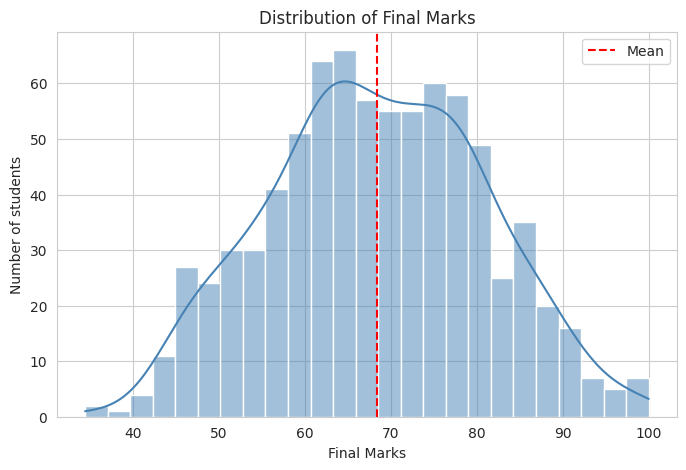

count    800.0
mean      68.4
std       12.5
min       34.4
25%       59.9
50%       68.4
75%       77.4
max      100.0
Name: Final Marks, dtype: float64


In [43]:
#Distribution of final marks (histogram)
plt.figure(figsize=(8, 5))
sns.histplot(train["Final Marks"], bins=25, kde=True, color="steelblue")
plt.axvline(train["Final Marks"].mean(), color="red", linestyle="--", label="Mean")
plt.title("Distribution of Final Marks")
plt.xlabel("Final Marks")
plt.ylabel("Number of students")
plt.legend()
plt.show()

print(train["Final Marks"].describe().round(1))

What to look for: a bell-shaped curve centered around 65 to 75, with a few students at the low end. These low scorers are the ones the predictor is meant to flag.

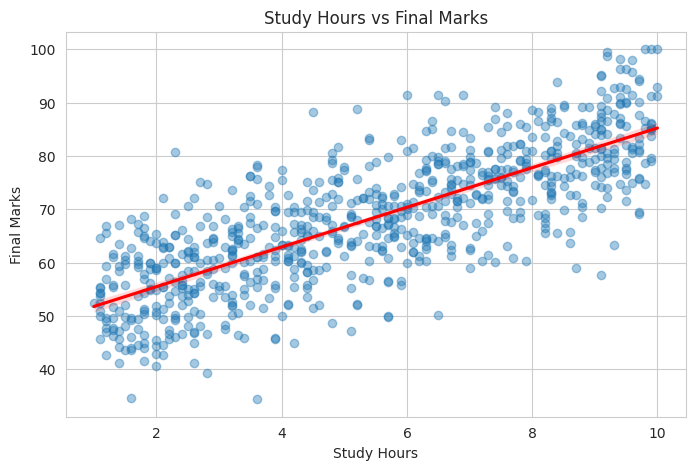

Correlation (Study Hours, Final Marks): 0.78


In [44]:
#Study hours vs marks (scatter plot)
plt.figure(figsize=(8, 5))
sns.regplot(data=train, x="Study Hours", y="Final Marks",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("Study Hours vs Final Marks")
plt.show()

corr = train["Study Hours"].corr(train["Final Marks"])
print("Correlation (Study Hours, Final Marks):", round(corr, 2))

a clear upward cloud and a strong positive correlation, probably around 0.7 to 0.8. Treat that range as my estimate and check your own output.

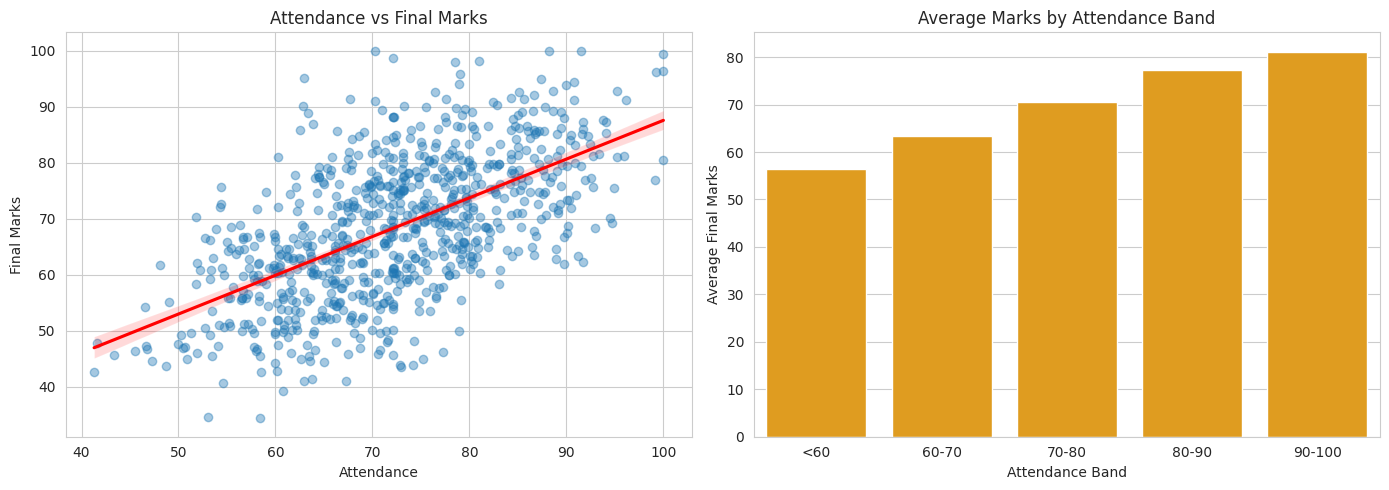

Attendance Band
<60       56.5
60-70     63.3
70-80     70.5
80-90     77.2
90-100    81.2
Name: Final Marks, dtype: float64
Correlation (Attendance, Final Marks): 0.59


In [45]:
#: Attendance vs marks (scatter plot and bar chart)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(data=train, x="Attendance", y="Final Marks",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("Attendance vs Final Marks")

train["Attendance Band"] = pd.cut(train["Attendance"],
                                  bins=[0, 60, 70, 80, 90, 100],
                                  labels=["<60", "60-70", "70-80", "80-90", "90-100"])
band_avg = train.groupby("Attendance Band", observed=True)["Final Marks"].mean()
sns.barplot(x=band_avg.index, y=band_avg.values, color="orange", ax=axes[1])
axes[1].set_title("Average Marks by Attendance Band")
axes[1].set_ylabel("Average Final Marks")

plt.tight_layout()
plt.show()

print(band_avg.round(1))
print("Correlation (Attendance, Final Marks):",
      round(train["Attendance"].corr(train["Final Marks"]), 2))

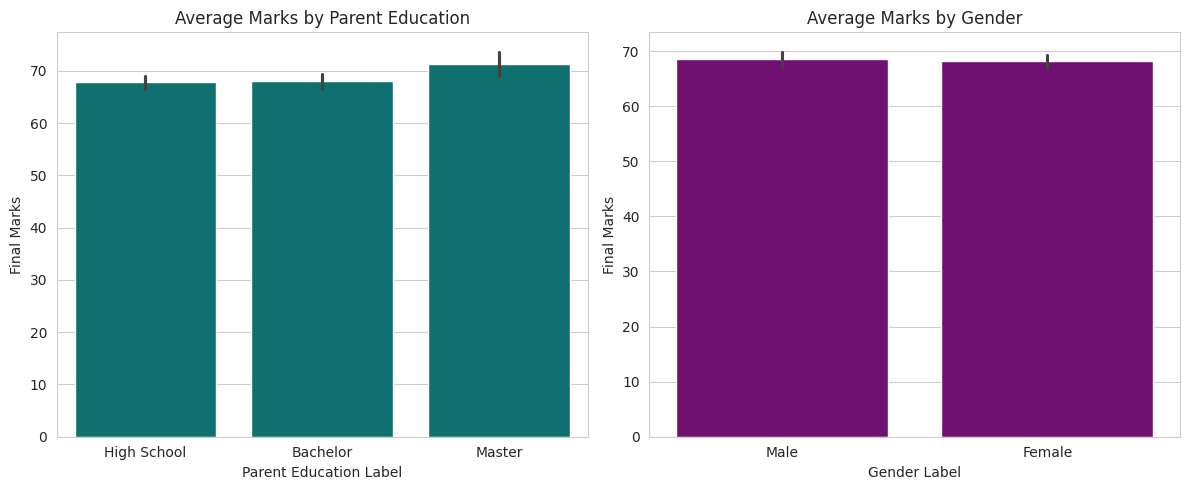

Parent Education Label
Bachelor       68.0
High School    67.8
Master         71.4
Name: Final Marks, dtype: float64
Gender Label
Female    68.2
Male      68.6
Name: Final Marks, dtype: float64


In [46]:
#Marks by parent education and gender (bar charts
train["Parent Education Label"] = train["Parent Education"].map(
    {0: "High School", 1: "Bachelor", 2: "Master"})
train["Gender Label"] = train["Gender_Male"].map({0: "Female", 1: "Male"})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=train, x="Parent Education Label", y="Final Marks",
            order=["High School", "Bachelor", "Master"], color="teal", ax=axes[0])
axes[0].set_title("Average Marks by Parent Education")

sns.barplot(data=train, x="Gender Label", y="Final Marks", color="purple", ax=axes[1])
axes[1].set_title("Average Marks by Gender")

plt.tight_layout()
plt.show()

print(train.groupby("Parent Education Label")["Final Marks"].mean().round(1))
print(train.groupby("Gender Label")["Final Marks"].mean().round(1))

We map the numeric codes back to readable labels, only for the charts. The model still uses the numbers.
sns.barplot calculates the average marks per group and draws a bar for each. The thin black line on each bar is the confidence interval, a range showing how certain that average is.
order=[...] forces High School, Bachelor, Master instead of alphabetical.

What to expect:

Parent education: a small step upward from High School to Master. The effect is real but modest.
Gender: the two bars should be about equal, because gender has no effect on marks in this dataset. If your bars differ by a point or two, that’s random variation. The confidence lines should overlap.

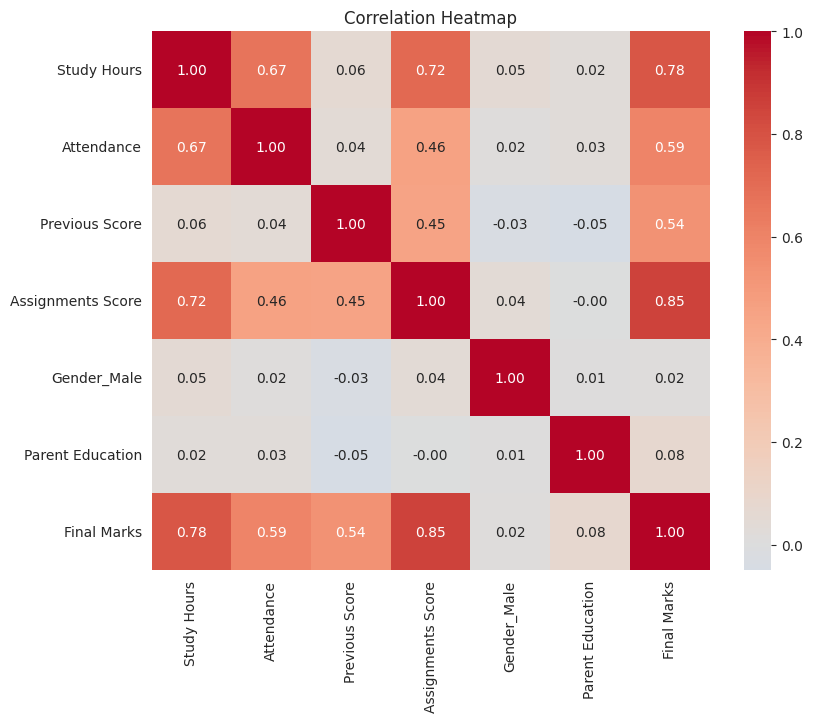

Assignments Score    0.85
Study Hours          0.78
Attendance           0.59
Previous Score       0.54
Parent Education     0.08
Gender_Male          0.02
Name: Final Marks, dtype: float64


In [47]:
#: Correlation heatmap
numeric = train[["Study Hours", "Attendance", "Previous Score",
                 "Assignments Score", "Gender_Male", "Parent Education", "Final Marks"]]
corr_matrix = numeric.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

print(corr_matrix["Final Marks"].drop("Final Marks").sort_values(ascending=False).round(2))

In [19]:
#Step 4: Model Building
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv")["Final Marks"]
y_test = pd.read_csv("y_test.csv")["Final Marks"]

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(800, 6) (200, 6) (800,) (200,)


What’s happening: We reload the four files saved in Step 2. We only saved the unscaled tables, so we recreate the scaled ones by fitting the scaler on the training data again, which gives exactly the same result as before. ["Final Marks"] turns the one-column file into a plain series of marks.

In [20]:
#Train the three models
lin_model = LinearRegression()
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
rf_model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)

lin_model.fit(X_train_scaled, y_train)
tree_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("All three models trained")

All three models trained


In [21]:
#Predict the test students’ marks
results = pd.DataFrame({
    "Actual": y_test.values,
    "Linear Regression": lin_model.predict(X_test_scaled),
    "Decision Tree": tree_model.predict(X_test),
    "Random Forest": rf_model.predict(X_test),
})

results = results.round(1)
print(results.head(10))
results.to_csv("student_predictions.csv", index=False)

   Actual  Linear Regression  Decision Tree  Random Forest
0    61.2               59.1           61.1           58.8
1    62.3               65.3           74.4           68.3
2    71.3               71.5           68.0           70.4
3    73.5               74.6           74.6           74.4
4    80.6               85.1           83.1           81.5
5    89.2               88.1           83.1           87.4
6    58.3               60.7           61.4           56.7
7    75.6               77.6           74.4           76.6
8    57.3               58.3           62.8           56.6
9    70.1               66.2           63.5           65.3


In [22]:
#Compare with the hidden formula
raw_lin = LinearRegression().fit(X_train, y_train)
raw_coef = pd.Series(raw_lin.coef_, index=X_train.columns)
print(raw_coef.round(2))
print("Intercept:", round(raw_lin.intercept_, 2))

Study Hours          2.16
Attendance           0.15
Previous Score       0.40
Assignments Score    0.26
Gender_Male         -0.27
Parent Education     1.46
dtype: float64
Intercept: 4.65


Assignments Score    0.705
Study Hours          0.121
Previous Score       0.109
Attendance           0.053
Parent Education     0.008
Gender_Male          0.004
dtype: float64


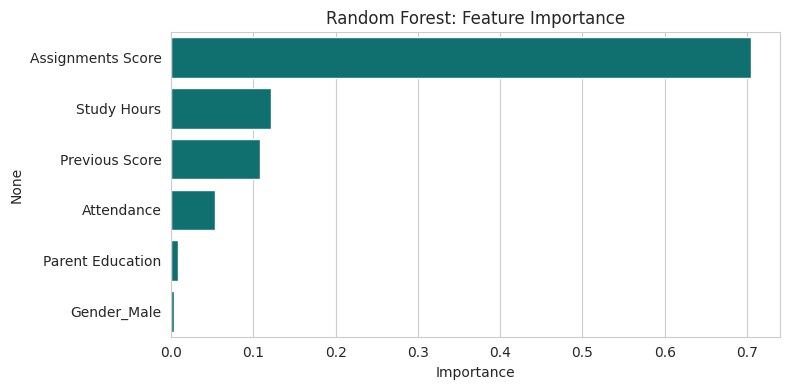

In [23]:
#Random Forest feature importance
importance = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=False)
print(importance.round(3))

import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 4))
sns.barplot(x=importance.values, y=importance.index, color="teal")
plt.title("Random Forest: Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [24]:
#STep 5
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


sns.set_style("whitegrid")

results = pd.read_csv("student_predictions.csv")
y_train = pd.read_csv("y_train.csv")["Final Marks"]

print(results.shape)
print(results.head())

(200, 4)
   Actual  Linear Regression  Decision Tree  Random Forest
0    61.2               59.1           61.1           58.8
1    62.3               65.3           74.4           68.3
2    71.3               71.5           68.0           70.4
3    73.5               74.6           74.6           74.4
4    80.6               85.1           83.1           81.5


In [25]:
#Calculate the metrics for every model
actual = results["Actual"]

# Baseline: predict the training average for everyone
results["Baseline (average)"] = y_train.mean()

rows = []
for col in ["Baseline (average)", "Linear Regression", "Decision Tree", "Random Forest"]:
    pred = results[col]
    mae = mean_absolute_error(actual, pred)
    mse = mean_squared_error(actual, pred)
    rows.append({
        "Model": col,
        "MAE": mae,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, pred),
    })

scores = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
print(scores.round(3))
scores.to_csv("student_model_scores.csv", index=False)

                Model     MAE      MSE    RMSE     R2
0   Linear Regression   3.359   18.143   4.259  0.884
1       Random Forest   3.763   22.764   4.771  0.854
2       Decision Tree   4.818   35.877   5.990  0.771
3  Baseline (average)  10.154  157.641  12.556 -0.008


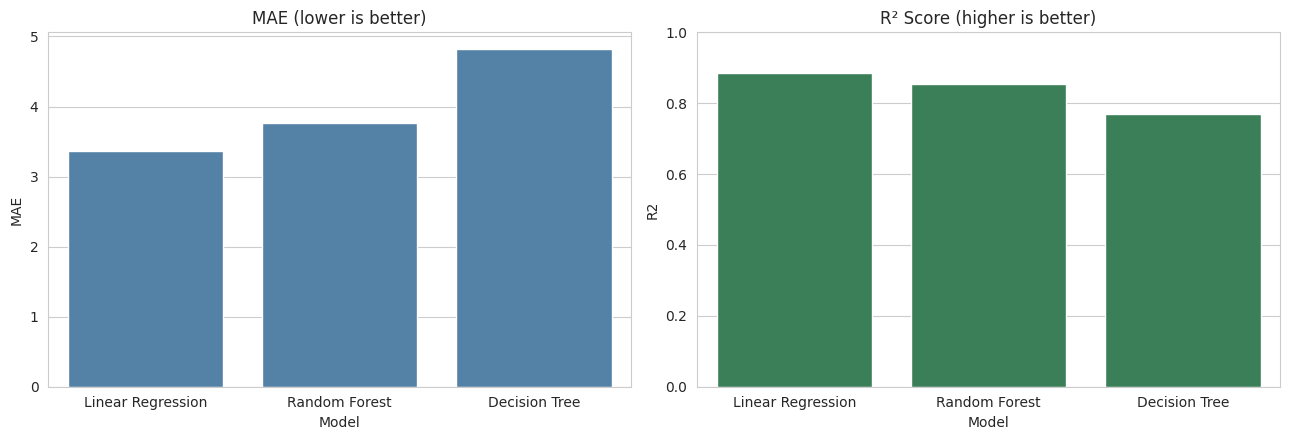

In [26]:
#Compare the models visually
plot_df = scores[scores["Model"] != "Baseline (average)"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=plot_df, x="Model", y="MAE", color="steelblue", ax=axes[0])
axes[0].set_title("MAE (lower is better)")

sns.barplot(data=plot_df, x="Model", y="R2", color="seagreen", ax=axes[1])
axes[1].set_title("R² Score (higher is better)")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

We drop the baseline so the real models are easy to compare, then draw MAE (shortest bar wins) and R² (tallest bar wins) side by side.

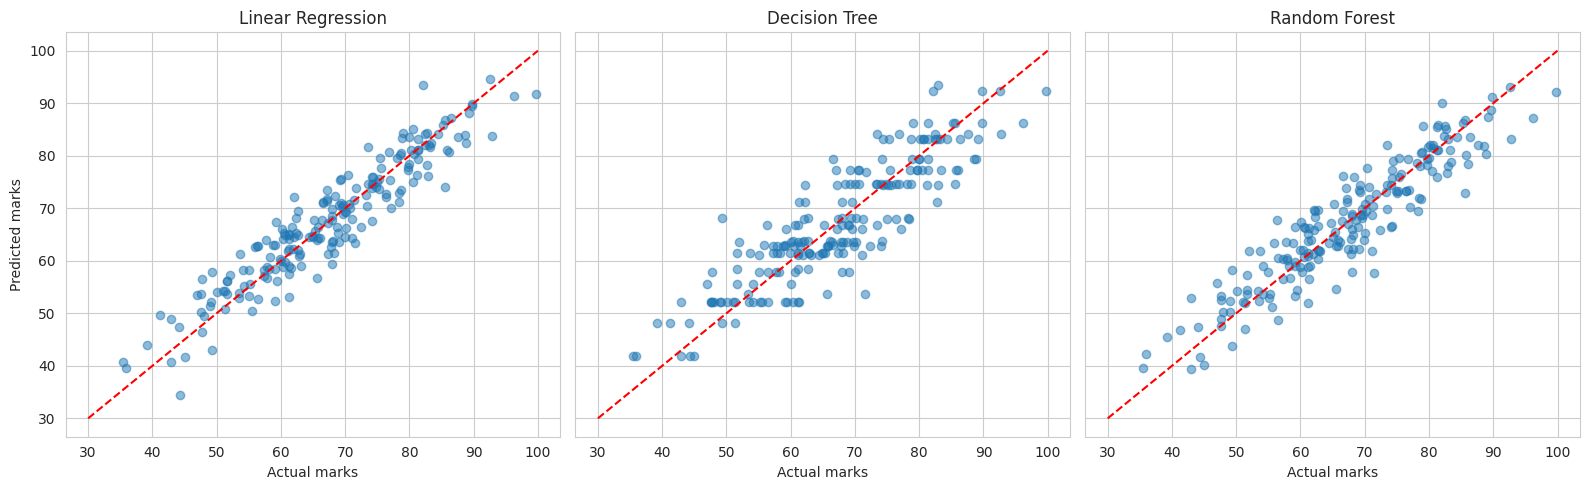

In [27]:
#Actual vs predicted for each model
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, col in zip(axes, ["Linear Regression", "Decision Tree", "Random Forest"]):
    ax.scatter(actual, results[col], alpha=0.5)
    ax.plot([30, 100], [30, 100], color="red", linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("Actual marks")
axes[0].set_ylabel("Predicted marks")

plt.tight_layout()
plt.show()

What’s happening:

Each dot is one test student, with the real mark on the x-axis and the predicted mark on the y-axis.
The red dashed line is the perfect-prediction line (predicted = actual). The closer the dots hug it, the better the model.
sharey=True gives all three charts the same scale, so you can compare them fairly.

What to look for: Linear Regression and Random Forest should form a tight band along the red line. The Decision Tree usually looks more “stepped”, with dots in horizontal rows, because each leaf of the tree predicts one fixed value for many students.

Best model by MAE: Linear Regression


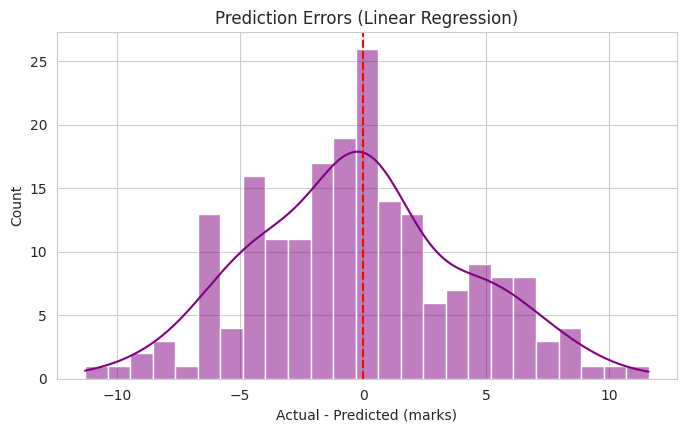

Average error (bias): -0.22
Typical spread of errors: 4.26


In [28]:
#Residuals of the best model
best = scores[scores["Model"] != "Baseline (average)"].iloc[0]["Model"]
print("Best model by MAE:", best)

residuals = actual - results[best]

plt.figure(figsize=(8, 4.5))
sns.histplot(residuals, bins=25, kde=True, color="purple")
plt.axvline(0, color="red", linestyle="--")
plt.title(f"Prediction Errors ({best})")
plt.xlabel("Actual - Predicted (marks)")
plt.show()

print("Average error (bias):", round(residuals.mean(), 2))
print("Typical spread of errors:", round(residuals.std(), 2))

What’s happening:

We pick the model with the lowest MAE, then calculate each student’s error and draw them as a histogram.
A good model gives a bell shape centered at 0, meaning it is not systematically too high or too low.

In [29]:
#Overfitting check (train vs test R²)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_test = pd.read_csv("y_test.csv")["Final Marks"]

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

setups = {
    "Linear Regression": (LinearRegression(), X_train_s, X_test_s),
    "Decision Tree": (DecisionTreeRegressor(max_depth=5, random_state=42), X_train, X_test),
    "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), X_train, X_test),
}

check = []
for name, (model, Xtr, Xte) in setups.items():
    model.fit(Xtr, y_train)
    check.append({
        "Model": name,
        "Train R2": r2_score(y_train, model.predict(Xtr)),
        "Test R2": r2_score(y_test, model.predict(Xte)),
    })

check = pd.DataFrame(check)
check["Gap"] = check["Train R2"] - check["Test R2"]
print(check.round(3))

               Model  Train R2  Test R2    Gap
0  Linear Regression     0.894    0.884  0.010
1      Decision Tree     0.869    0.771  0.099
2      Random Forest     0.981    0.855  0.127
